In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [38]:
df = pd.read_csv('Social_Network_Ads.csv')

In [39]:
df.head()

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [40]:
df.drop(columns=["User ID","Gender"], inplace=True)

In [41]:
df.sample(5)

,Age,EstimatedSalary,Purchased
197,20,36000,0
219,59,143000,1
319,36,60000,0
5,27,58000,0
105,21,72000,0


## Train Test Split

In [42]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(
    df.drop(['Purchased'],axis=1),
    df['Purchased'],
    test_size=0.2,
    random_state=0
)

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

# fit_transform training data
x_train_scaled = scaler.fit_transform(x_train)

# transform test data
x_test_scaled = scaler.transform(x_test)




In [45]:
x_train

,Age,EstimatedSalary
336,58,144000
64,59,83000
55,24,55000
106,26,35000
300,58,38000
...,...,...
323,48,30000
192,29,43000
117,36,52000
47,27,54000


In [46]:
x_train_scaled

array([[ 1.92295008e+00,  2.14601566e+00],
       [ 2.02016082e+00,  3.78719297e-01],
       [-1.38221530e+00, -4.32498705e-01],
       [-1.18779381e+00, -1.01194013e+00],
       [ 1.92295008e+00, -9.25023920e-01],
       [ 3.67578135e-01,  2.91803083e-01],
       [ 1.73156642e-01,  1.46942725e-01],
       [ 2.02016082e+00,  1.74040666e+00],
       [ 7.56421121e-01, -8.38107706e-01],
       [ 2.70367388e-01, -2.87638347e-01],
       [ 3.67578135e-01, -1.71750061e-01],
       [-1.18475597e-01,  2.20395980e+00],
       [-1.47942605e+00, -6.35303205e-01],
       [-1.28500455e+00, -1.06988428e+00],
       [-1.38221530e+00,  4.07691369e-01],
       [-1.09058306e+00,  7.55356227e-01],
       [-1.47942605e+00, -2.00722133e-01],
       [ 9.50842613e-01, -1.06988428e+00],
       [ 9.50842613e-01,  5.81523798e-01],
       [ 3.67578135e-01,  9.87132798e-01],
       [ 5.61999628e-01, -8.96051849e-01],
       [-6.04529329e-01,  1.45068594e+00],
       [-2.12648508e-02, -5.77359062e-01],
       [-6.

In [48]:
x_train_scaled = pd.DataFrame(x_train_scaled, columns=x_train.columns)
x_test_scaled = pd.DataFrame(x_test_scaled, columns=x_test.columns)

In [50]:
x_train_scaled.sample(5)

,Age,EstimatedSalary
37,-0.701740,0.552552
237,-0.896162,-0.258666
316,-0.896162,-0.780164
146,-0.312897,0.784328
41,2.117372,0.929189


In [51]:
np.round(x_train.describe(),1)

,Age,EstimatedSalary
count,320.0,320.0
mean,38.2,69928.1
std,10.3,34570.1
min,18.0,15000.0
25%,30.0,43000.0
50%,38.0,69500.0
75%,46.0,88000.0
max,60.0,150000.0


In [52]:
np.round(x_train_scaled.describe(),1)

,Age,EstimatedSalary
count,320.0,320.0
mean,0.0,0.0
std,1.0,1.0
min,-2.0,-1.6
25%,-0.8,-0.8
50%,-0.0,-0.0
75%,0.8,0.5
max,2.1,2.3


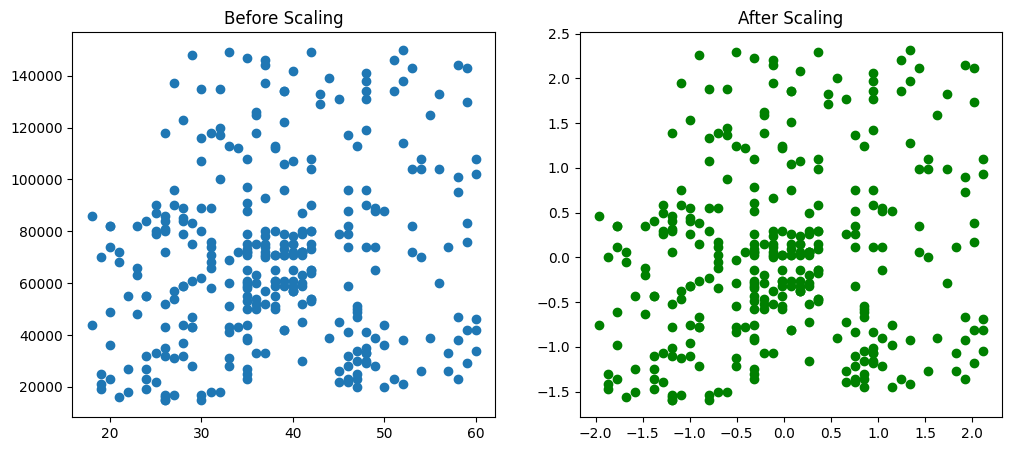

In [55]:
fig, (ax1,ax2) = plt.subplots(ncols=2,figsize=(12,5))
ax1.scatter(x_train['Age'], x_train['EstimatedSalary'])
ax1.set_title('Before Scaling')
ax2.scatter(x_train_scaled['Age'], x_train_scaled['EstimatedSalary'], color='green')
ax2.set_title('After Scaling')
plt.show()

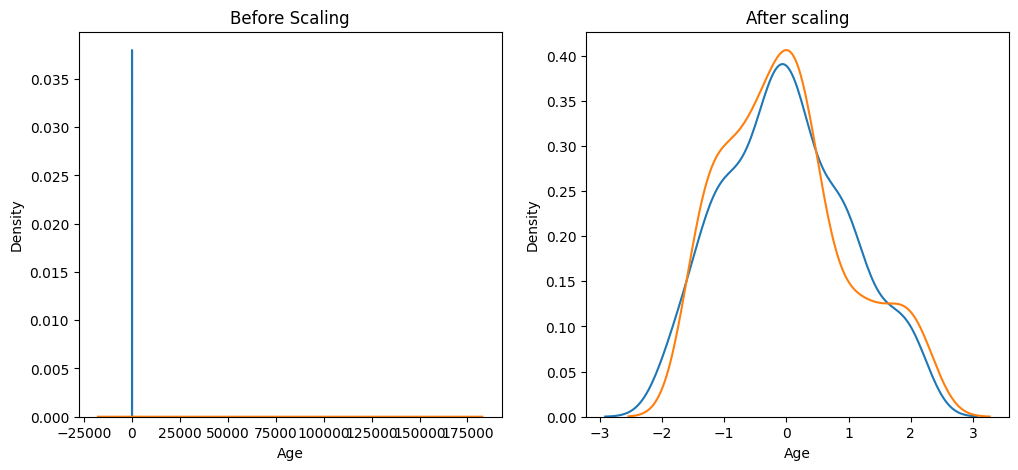

In [58]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12,5))
# Before Scaling
sns.kdeplot(x_train['Age'],ax=ax1)
sns.kdeplot(x_train['EstimatedSalary'],ax=ax1)
ax1.set_title('Before Scaling')

# After Scaling
sns.kdeplot(x_train_scaled['Age'],ax=ax2)
sns.kdeplot(x_train_scaled['EstimatedSalary'], ax=ax2)
ax2.set_title('After scaling')
plt.show()

<Axes: title={'center': 'Age Distribution After Scaling'}, xlabel='Age', ylabel='Density'>

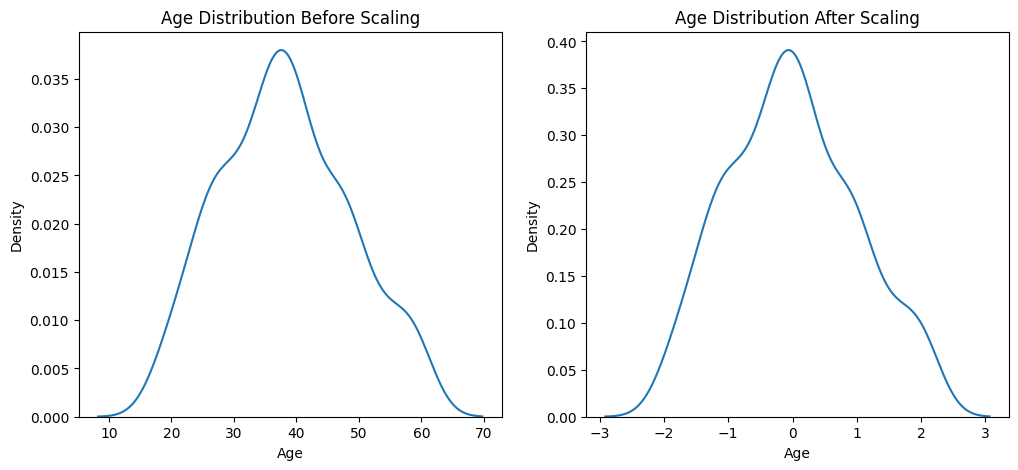

In [59]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))
# Before Scaling
ax1.set_title('Age Distribution Before Scaling')
sns.kdeplot(x_train['Age'],ax=ax1)

# After Scaling
ax2.set_title('Age Distribution After Scaling')
sns.kdeplot(x_train_scaled['Age'],ax=ax2)

<Axes: title={'center': 'EstimatedSalary Distribution After Scaling'}, xlabel='EstimatedSalary', ylabel='Density'>

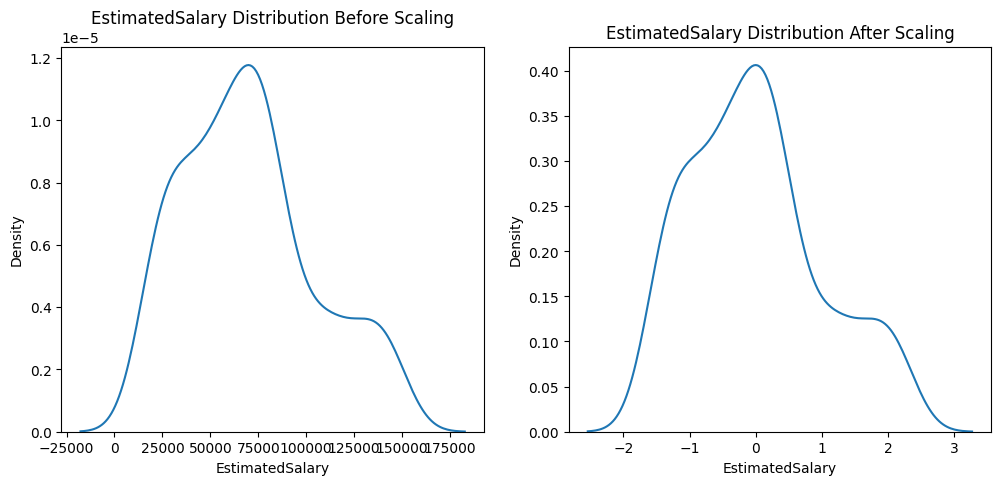

In [60]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))
# Before Scaling
ax1.set_title('EstimatedSalary Distribution Before Scaling')
sns.kdeplot(x_train['EstimatedSalary'],ax=ax1)

# After Scaling
ax2.set_title('EstimatedSalary Distribution After Scaling')
sns.kdeplot(x_train_scaled['EstimatedSalary'],ax=ax2)